In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
import seaborn as sns
import datetime as dt
from sklearn.preprocessing import StandardScaler

In [3]:
from sklearn.cluster import KMeans
df = pd.read_csv('./sales_data_sample.csv', encoding='unicode_escape')

In [4]:
to_drop = ['ADDRESSLINE1', 'ADDRESSLINE2', 'STATE', 'POSTALCODE', 'PHONE']
df = df.drop(to_drop, axis=1)

In [5]:
df['ORDERDATE'] = pd.to_datetime(df['ORDERDATE'])
snapshot_date = df['ORDERDATE'].max() + dt.timedelta(days=1)

In [6]:
df_RFM = df.groupby('CUSTOMERNAME').agg({
    'ORDERDATE': lambda x: (snapshot_date - x.max()).days,
    'ORDERNUMBER': 'count',
    'SALES': 'sum'
})

In [7]:
df_RFM.rename(columns={'ORDERDATE': 'Recency',
                       'ORDERNUMBER': 'Frequency',
                       'SALES': 'MonetaryValue'}, inplace=True)

In [8]:
df_RFM['M'] = pd.qcut(df_RFM['MonetaryValue'], q=4, labels=range(1,5))
df_RFM['R'] = pd.qcut(df_RFM['Recency'], q=4, labels=list(range(4,0,-1)))
df_RFM['F'] = pd.qcut(df_RFM['Frequency'], q=4, labels=range(1,5))

In [9]:
df_RFM['RFM_Score'] = df_RFM[['R','F','M']].sum(axis=1)

In [10]:
def rfm_level(df):
    if df['RFM_Score'] >= 10:
        return 'High Value Customer'
    elif 6 <= df['RFM_Score'] < 10:
        return 'Mid Value Customer'
    else:
        return 'Low Value Customer'

In [11]:
df_RFM['RFM_Level'] = df_RFM.apply(rfm_level, axis=1)

In [12]:
data = df_RFM[['Recency', 'Frequency', 'MonetaryValue']]
data_log = np.log1p(data)

In [13]:
scaler = StandardScaler()
data_normalized = pd.DataFrame(scaler.fit_transform(data_log),
                               index=data_log.index,
                               columns=data_log.columns)

In [14]:
sse = {}
for k in range(1, 21):
    kmeans = KMeans(n_clusters=k, random_state=1)
    kmeans.fit(data_normalized)
    sse[k] = kmeans.inertia_

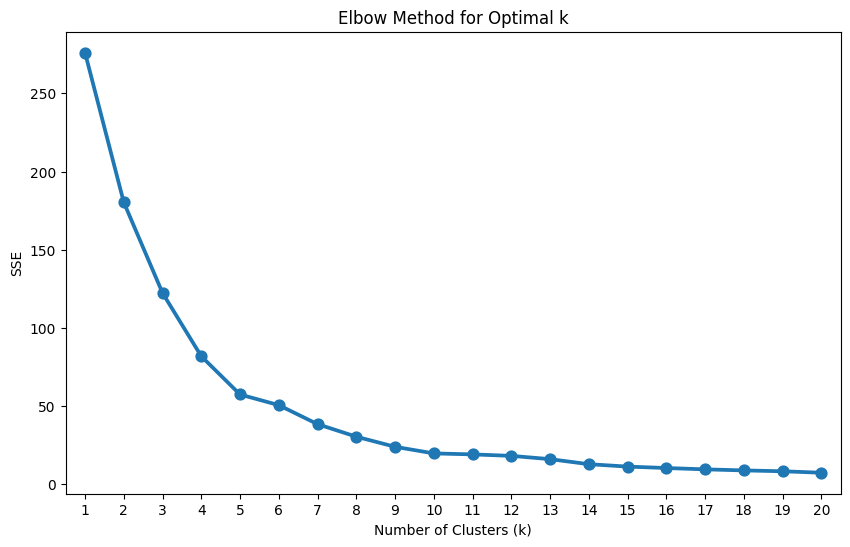

In [15]:
plt.figure(figsize=(10,6))
plt.title('Elbow Method for Optimal k')
plt.xlabel('Number of Clusters (k)')
plt.ylabel('SSE')
sns.pointplot(x=list(sse.keys()), y=list(sse.values()))
plt.show()

In [16]:
kmeans = KMeans(n_clusters=5, random_state=1)
kmeans.fit(data_normalized)
cluster_labels = kmeans.labels_

In [17]:
data_rfm = data.assign(Cluster=cluster_labels)
data_rfm.head()

,Recency,Frequency,MonetaryValue,Cluster
CUSTOMERNAME,,,,
"AV Stores, Co.",196,51,157807.81,4
Alpha Cognac,65,20,70488.44,2
Amica Models & Co.,265,26,94117.26,2
"Anna's Decorations, Ltd",84,46,153996.13,4
Atelier graphique,188,7,24179.96,1
